## 1 . Nhập dữ liệu và thống kê những thông tin cơ bản của các thuộc tính.

### 1.1 Import các thư viện thao tác và trực quan hóa dữ liệu

Sử dụng các thư viện Pandas, NumPy, Matplotlib và Seaborn để đọc, xử lý, thống kê và trực quan hóa dữ liệu Bank Marketing.

In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

### 1.2 Đọc dữ liệu đầu vào

Đọc dữ liệu Bank Marketing từ tệp CSV. Tập dữ liệu được sử dụng cần có các thuộc tính Job, Marial, Education, Default, Loan, Duration, Cons.price.idx và Subscribe theo đề bài.

In [47]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Đọc file đã có trong Google Colab
df = pd.read_csv("/content/bank-full.csv", sep=";")

# Chuẩn hóa tên cột để dễ sử dụng
df.columns = df.columns.str.strip()

print("Đọc dữ liệu thành công!")
print("Kích thước dữ liệu:", df.shape)
print("\nDanh sách thuộc tính:")
print(df.columns.tolist())

display(df.head())


Đọc dữ liệu thành công!
Kích thước dữ liệu: (45211, 17)

Danh sách thuộc tính:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


### 1.3 Xem xét dữ liệu ban đầu

Sử dụng hàm `head()` để xem các dòng dữ liệu đầu tiên và kiểm tra cách biểu diễn thông tin khách hàng trong tập dữ liệu.

In [48]:
df.head(12)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
5,35,management,married,tertiary,no,231,yes,no,unknown,5,may,139,1,-1,0,unknown,no
6,28,management,single,tertiary,no,447,yes,yes,unknown,5,may,217,1,-1,0,unknown,no
7,42,entrepreneur,divorced,tertiary,yes,2,yes,no,unknown,5,may,380,1,-1,0,unknown,no
8,58,retired,married,primary,no,121,yes,no,unknown,5,may,50,1,-1,0,unknown,no
9,43,technician,single,secondary,no,593,yes,no,unknown,5,may,55,1,-1,0,unknown,no


### 1.4 Xem thông tin tổng quan về tập dữ liệu với info()

Sử dụng `info()` để xem số lượng bản ghi, tên thuộc tính, kiểu dữ liệu và số giá trị không rỗng của từng cột.

In [49]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


### 1.5 Thống kê chỉ số của các thuộc tính định lượng

Sử dụng `describe()` để thống kê số lượng giá trị, giá trị trung bình, độ lệch chuẩn, giá trị nhỏ nhất, lớn nhất và các tứ phân vị của những thuộc tính định lượng.

In [50]:
numeric_cols = df.select_dtypes(include="number").columns
display(df[numeric_cols].describe())

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


## 2 . Lấy ra 5 thuộc tính có số lượng giá trị rỗng nhiều nhất

Thống kê số lượng và tỷ lệ giá trị thiếu trong từng thuộc tính, sau đó sắp xếp giảm dần để xác định 5 thuộc tính có số lượng giá trị rỗng nhiều nhất.

Ngoài các giá trị thiếu dạng NaN, cần kiểm tra giá trị `unknown` vì dữ liệu Bank Marketing có thể dùng giá trị này để biểu diễn thông tin chưa xác định.

In [51]:
df_missing = df.copy()

for col in df_missing.select_dtypes(include="object").columns:
    df_missing[col] = df_missing[col].replace(
        r"(?i)^\s*unknown\s*$", np.nan, regex=True
    )

missing_stats = pd.DataFrame({
    "So_luong_rong": df_missing.isnull().sum(),
    "Ty_le_rong (%)": df_missing.isnull().mean() * 100
})

display(
    missing_stats.sort_values(
        by="So_luong_rong",
        ascending=False
    ).head(5)
)

,So_luong_rong,Ty_le_rong (%)
poutcome,36959,81.747805
contact,13020,28.798301
education,1857,4.107407
job,288,0.637013
age,0,0.000000


## 3 . Xem xét thống kê giữa thuộc tính nghề nghiệp (Job), trình độ học vấn (Education) và khả năng đăng ký (Subscribe)

Khảo sát mối quan hệ giữa nghề nghiệp, trình độ học vấn và kết quả đăng ký chương trình gửi tiền có kỳ hạn.

Sử dụng biểu đồ để so sánh số lượng khách hàng đăng ký và không đăng ký giữa các nhóm. Qua đó, nhận xét sự khác biệt quan sát được trong dữ liệu.

Các cột hiện tại: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


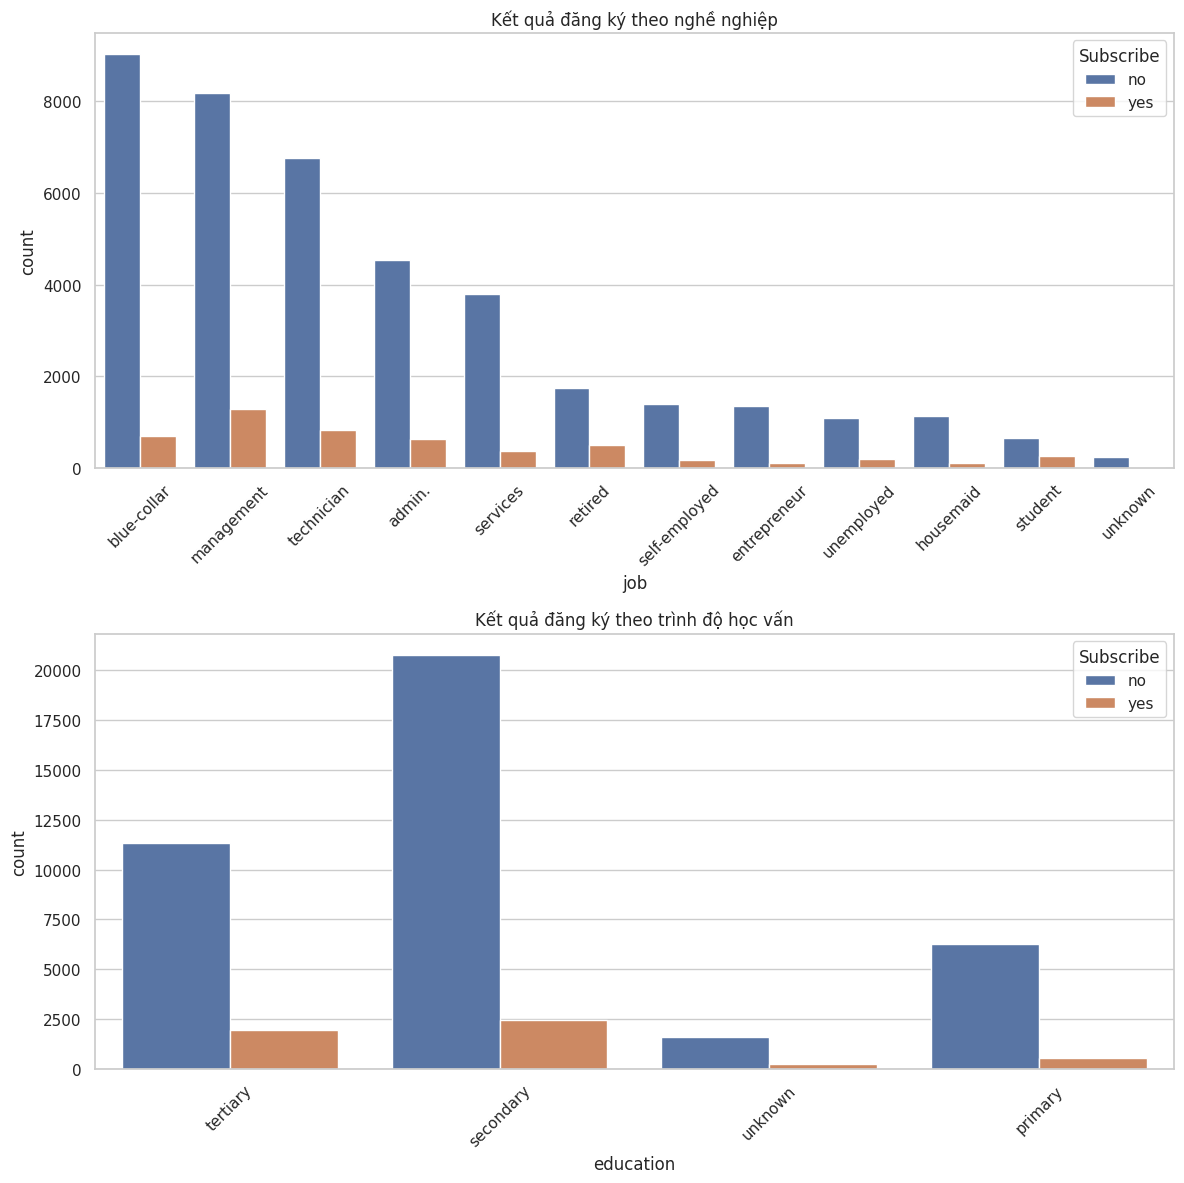

In [52]:

# 1. Xác định cột kết quả đăng ký
print("Các cột hiện tại:", df.columns.tolist())

target_col = next(
    (col for col in df.columns
     if col.strip().lower() in ["y", "subscribe"]),
    None
)

if target_col is None:
    raise ValueError("Không tìm thấy cột y hoặc Subscribe!")

# 2. Chuẩn hóa tên cột
df = df.rename(columns={target_col: "Subscribe"})

# 3. Vẽ biểu đồ
fig, axes = plt.subplots(2, 1, figsize=(12, 12))

sns.countplot(
    data=df,
    x="job",
    hue="Subscribe",
    ax=axes[0],
    order=df["job"].value_counts().index
)
axes[0].set_title("Kết quả đăng ký theo nghề nghiệp")
axes[0].tick_params(axis="x", rotation=45)

sns.countplot(
    data=df,
    x="education",
    hue="Subscribe",
    ax=axes[1]
)
axes[1].set_title("Kết quả đăng ký theo trình độ học vấn")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


## 4 . Xem xét thống kê giữa thuộc tính tín dụng mặc định (Default), khoản vay (Loan) với khả năng đăng ký (Subscribe)

Khảo sát sự khác biệt về kết quả đăng ký giữa các nhóm khách hàng theo tình trạng tín dụng mặc định và tình trạng khoản vay.

Sử dụng bảng chéo và biểu đồ tỷ lệ để so sánh kết quả đăng ký giữa các nhóm. Cần lưu ý rằng một số giá trị có thể là `unknown`, do đó phải xem xét dữ liệu chưa xác định khi diễn giải kết quả.

Các cột trong dữ liệu:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'Subscribe']


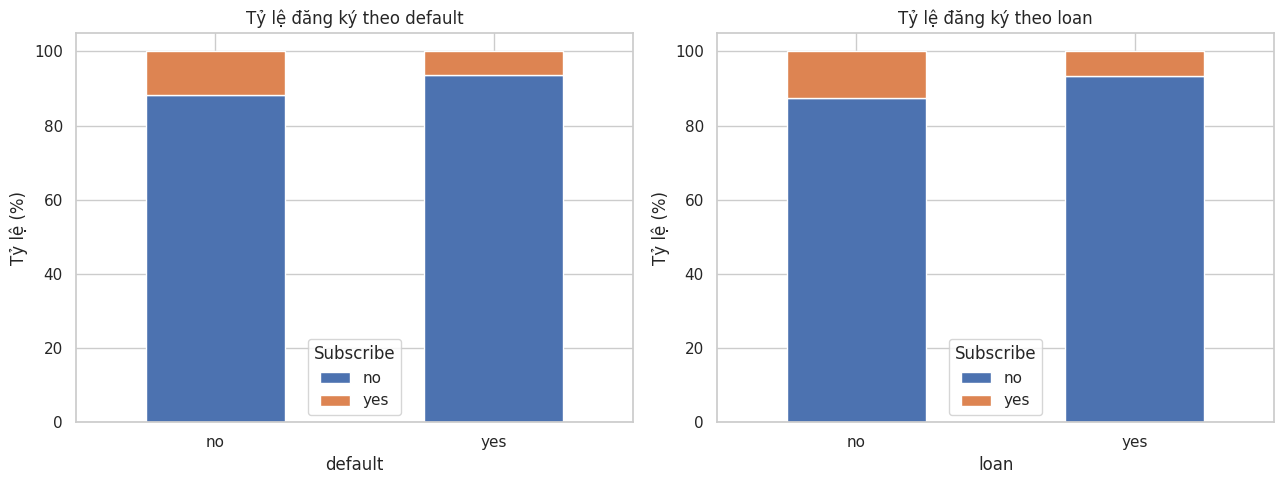

In [53]:

# Kiểm tra tên các cột hiện có
print("Các cột trong dữ liệu:")
print(df.columns.tolist())

# Tìm cột kết quả đăng ký
target_col = next(
    (col for col in df.columns
     if col.strip().lower() in ["subscribe", "y"]),
    None
)

if target_col is None:
    raise ValueError(
        "Không tìm thấy cột kết quả đăng ký. "
        "Hãy kiểm tra danh sách cột ở trên."
    )

# Chuẩn hóa tên cột để sử dụng thống nhất
df = df.rename(columns={target_col: "Subscribe"})

# Vẽ biểu đồ theo Default và Loan
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for col, ax in zip(["default", "loan"], axes):
    if col not in df.columns:
        ax.set_title(f"Không tìm thấy cột {col}")
        continue

    rate = pd.crosstab(
        df[col],
        df["Subscribe"],
        normalize="index"
    ) * 100

    rate.plot(kind="bar", stacked=True, ax=ax)

    ax.set_title(f"Tỷ lệ đăng ký theo {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Tỷ lệ (%)")
    ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


## 5 . Thống kê thời lượng liên hệ (Duration) và khảo sát mối quan hệ với kết quả đăng ký

Thống kê thời lượng của lần liên hệ cuối cùng với khách hàng. Tiếp theo, khảo sát mối quan hệ giữa thời lượng liên hệ và kết quả đăng ký gửi tiền có kỳ hạn.

Chia thời lượng liên hệ thành các nhóm để thuận tiện cho việc so sánh tỷ lệ đăng ký. Kết quả chỉ phản ánh mối liên hệ quan sát được trong dữ liệu, không khẳng định quan hệ nhân quả.

Subscribe,no,yes
Duration_group,,
0-120 giây,98.50,1.50
121-300 giây,91.43,8.57
301-600 giây,80.85,19.15
Trên 600 giây,51.64,48.36


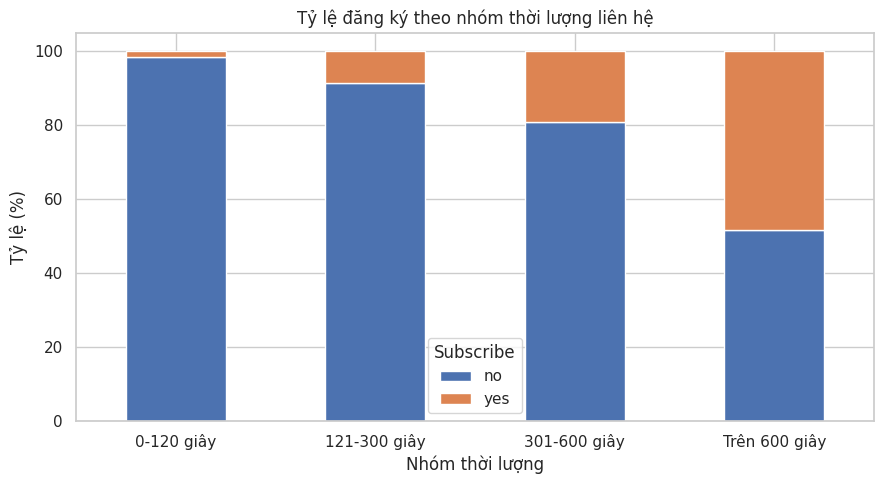

In [54]:
df_duration = df.copy()

df_duration["Duration_group"] = pd.cut(
    df_duration["duration"],
    bins=[-1, 120, 300, 600, np.inf],
    labels=["0-120 giây", "121-300 giây",
            "301-600 giây", "Trên 600 giây"]
)

duration_rate = pd.crosstab(
    df_duration["Duration_group"],
    df_duration["Subscribe"],
    normalize="index"
) * 100

display(duration_rate.round(2))

duration_rate.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Tỷ lệ đăng ký theo nhóm thời lượng liên hệ")
plt.xlabel("Nhóm thời lượng")
plt.ylabel("Tỷ lệ (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 6 . Tiền xử lý dữ liệu

### 6.1 Xem xét và loại bỏ thuộc tính không cần thiết

Dựa vào mục tiêu bài toán và kết quả khảo sát, xem xét các thuộc tính có cần thiết cho phân tích hay không. Không loại bỏ các thuộc tính được yêu cầu trong đề bài nếu chưa có căn cứ phù hợp.

In [55]:
required_columns = [
    "job", "marital", "education", "default",
    "loan", "duration", "cons.price.idx", "y"
]

available_columns = [
    col for col in required_columns
    if col in df.columns
]

df_clean = df[available_columns].copy()

print("Các thuộc tính được giữ lại:")
print(df_clean.columns.tolist())

Các thuộc tính được giữ lại:
['job', 'marital', 'education', 'default', 'loan', 'duration']


### 6.2 Xử lý các giá trị thiếu

Chuyển các giá trị `unknown` thành giá trị thiếu để thuận tiện cho quá trình xử lý. Với thuộc tính định lượng, có thể sử dụng trung vị; với thuộc tính phân loại, có thể sử dụng giá trị xuất hiện nhiều nhất.

Việc điền giá trị cần được cân nhắc dựa trên kết quả khảo sát và không nên thay thế dữ liệu một cách tùy tiện.

In [56]:
for col in df_clean.select_dtypes(include="object").columns:
    df_clean[col] = df_clean[col].replace(
        r"(?i)^\s*unknown\s*$", np.nan, regex=True
    )

for col in df_clean.columns:
    if df_clean[col].isnull().any():
        if pd.api.types.is_numeric_dtype(df_clean[col]):
            df_clean[col] = df_clean[col].fillna(
                df_clean[col].median()
            )
        else:
            mode_values = df_clean[col].mode(dropna=True)
            if not mode_values.empty:
                df_clean[col] = df_clean[col].fillna(
                    mode_values.iloc[0]
                )

print("Số giá trị thiếu còn lại:", df_clean.isnull().sum().sum())

Số giá trị thiếu còn lại: 0


### 6.3 Chuyển đổi kiểu dữ liệu và mã hóa thuộc tính

Kiểm tra kiểu dữ liệu của các thuộc tính. Chuyển các thuộc tính phân loại sang dạng số bằng One-hot Encoding để chuẩn bị cho việc sử dụng trong các thuật toán học máy.

Thuộc tính mục tiêu `Subscribe` được giữ lại riêng để phân biệt khách hàng có đăng ký và không đăng ký.

In [57]:
df_clean = df_clean.rename(columns={"y": "Subscribe"})

categorical_cols = [
    col for col in df_clean.select_dtypes(include="object").columns
    if col != "Subscribe"
]

df_encoded = pd.get_dummies(
    df_clean,
    columns=categorical_cols,
    dtype=int
)

print("Kích thước sau mã hóa:", df_encoded.shape)
display(df_encoded.head())

Kích thước sau mã hóa: (45211, 22)


,duration,job_admin.,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_student,...,marital_divorced,marital_married,marital_single,education_primary,education_secondary,education_tertiary,default_no,default_yes,loan_no,loan_yes
0,261,0,0,0,0,1,0,0,0,0,...,0,1,0,0,0,1,1,0,1,0
1,151,0,0,0,0,0,0,0,0,0,...,0,0,1,0,1,0,1,0,1,0
2,76,0,0,1,0,0,0,0,0,0,...,0,1,0,0,1,0,1,0,0,1
3,92,0,1,0,0,0,0,0,0,0,...,0,1,0,0,1,0,1,0,1,0
4,198,0,1,0,0,0,0,0,0,0,...,0,0,1,0,1,0,1,0,1,0


### 6.4 Kiểm tra kết quả sau tiền xử lý

Sau khi hoàn thành tiền xử lý, kiểm tra lại kiểu dữ liệu, các giá trị thiếu, các dòng trùng lặp và kích thước tập dữ liệu. Lưu kết quả để sử dụng trong những bước phân tích tiếp theo.

In [58]:
print("Kích thước dữ liệu:", df_encoded.shape)

print("\nSố giá trị thiếu:")
print(df_encoded.isnull().sum().sum())

print("\nSố dòng trùng lặp:")
print(df_encoded.duplicated().sum())

print("\nKiểu dữ liệu:")
display(df_encoded.dtypes.to_frame("Kieu_du_lieu"))

df_clean.to_csv(
    "bank_marketing_clean.csv",
    index=False,
    encoding="utf-8-sig"
)

df_encoded.to_csv(
    "bank_marketing_encoded.csv",
    index=False,
    encoding="utf-8-sig"
)

Kích thước dữ liệu: (45211, 22)

Số giá trị thiếu:
0

Số dòng trùng lặp:
21443

Kiểu dữ liệu:


,Kieu_du_lieu
duration,int64
job_admin.,int64
job_blue-collar,int64
job_entrepreneur,int64
job_housemaid,int64
job_management,int64
job_retired,int64
job_self-employed,int64
job_services,int64
job_student,int64
